<a href="https://colab.research.google.com/github/San-Maansson/Stock_Analysis/blob/main/Adv_ML%26AI_Applications_in_Finance.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

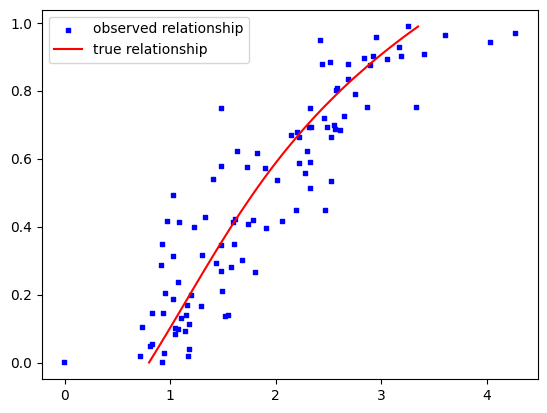

In [32]:
"""
Synthetic data
"""
import numpy as np
import matplotlib.pyplot as plt
import os
import pandas as pd

#Set random seed
np.random.seed(1)

#Synthetic data
def true_function(x):
    """
    True non-linear relationship
    """
    return 0.8 + 2*x - 0.5*x**2 + 0.8*x**3 + 0.3*x**4

n_samples = 100
X = np.sort(np.random.rand(n_samples))
error = np.random.normal(scale = 0.4, size = X.shape)
y = true_function(X) + error
X = X.reshape(-1, 1)

#plt.scatter([y, true_function(X)], X)
#plt.show()

fig = plt.figure()
ax1 = fig.add_subplot(111)

ax1.scatter(y, X, s=10, c='b', marker="s", label='observed relationship')
ax1.plot(true_function(X), X, c='r', label='true relationship')
plt.legend(loc='upper left')
plt.savefig('Figure0.png')
plt.show()

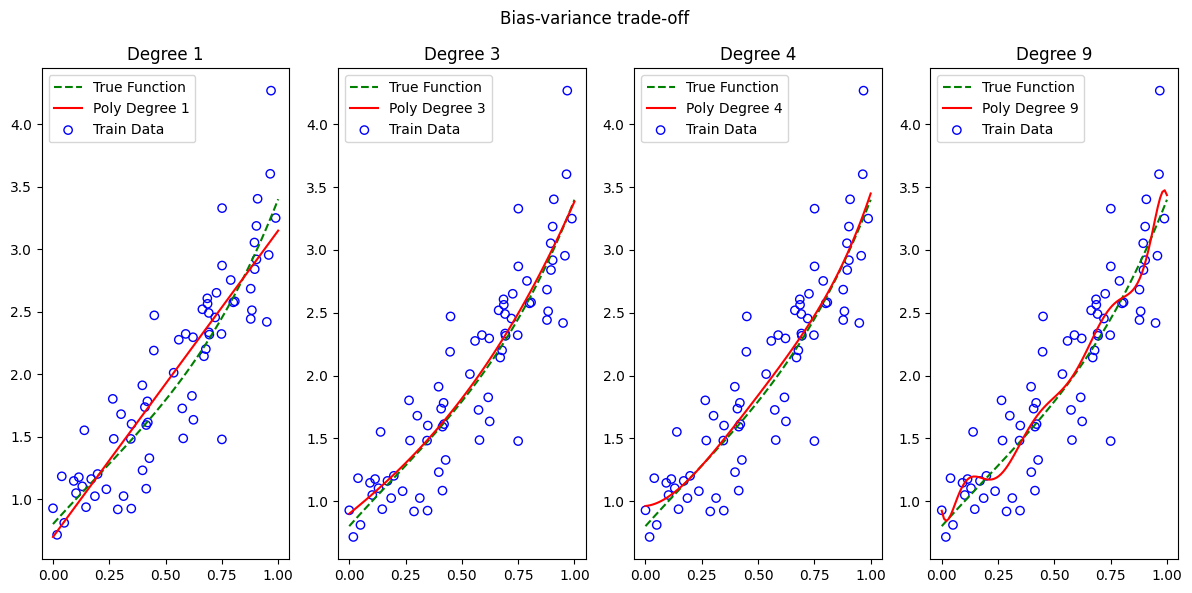

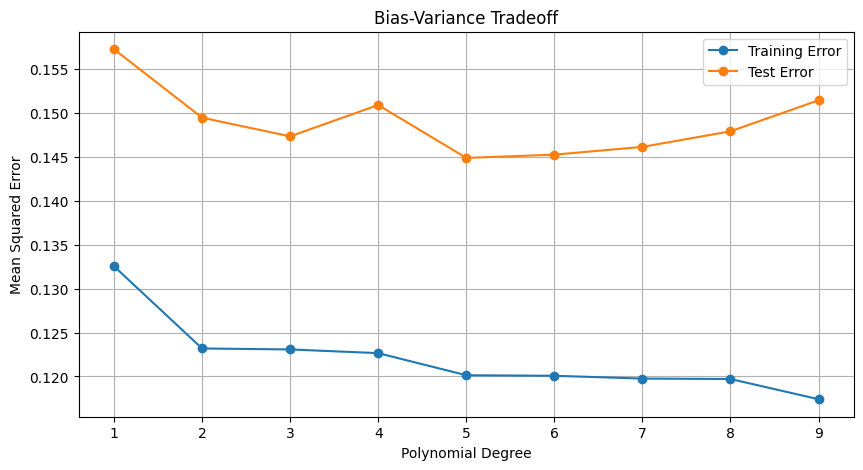

In [28]:
"""
Illustration of bias-variance tradeoff
"""

from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import train_test_split

#Set random seed
np.random.seed(1)

#Synthetic data
def true_function(x):
    """
    True non-linear relationship
    """
    return 0.8 + 2*x - 0.5*x**2 + 0.8*x**3 + 0.3*x**4

n_samples = 100
X = np.sort(np.random.rand(n_samples))
error = np.random.normal(scale = 0.4, size = X.shape)
y = true_function(X) + error
X = X.reshape(-1, 1)

#Training and test data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3)

#Polynomials
degrees = range(1, 10)

train_errors = []
test_errors = []

plt.figure(figsize=(12, 6))

for i, degree in enumerate(degrees, 1):
    model = make_pipeline(PolynomialFeatures(degree), LinearRegression())
    model.fit(X_train, y_train)

    # Predict on training and test sets
    y_train_pred = model.predict(X_train)
    y_test_pred = model.predict(X_test)

    train_mse = mean_squared_error(y_train, y_train_pred)
    test_mse = mean_squared_error(y_test, y_test_pred)

    train_errors.append(train_mse)
    test_errors.append(test_mse)

    # Plot for selected degrees
    if degree in [1, 3, 4, 9]:
        plt.subplot(1, 4, [1, 3, 4, 9].index(degree) + 1)
        x_plot = np.linspace(0, 1, 100).reshape(-1, 1)
        y_plot = model.predict(x_plot)
        plt.plot(x_plot, true_function(x_plot), 'g--', label='True Function')
        plt.plot(x_plot, y_plot, 'r-', label=f'Poly Degree {degree}')
        plt.scatter(X_train, y_train, facecolors='none', edgecolors='b', label='Train Data')
        plt.title(f'Degree {degree}')
        plt.legend()

plt.suptitle('Bias-variance trade-off', fontsize = 12)
plt.tight_layout()
plt.savefig('Figure1.png')

# Plot training and test errors
plt.figure(figsize=(10, 5))
plt.plot(degrees, train_errors, label='Training Error', marker='o')
plt.plot(degrees, test_errors, label='Test Error', marker='o')
plt.xlabel('Polynomial Degree')
plt.ylabel('Mean Squared Error')
plt.title('Bias-Variance Tradeoff')
plt.legend()
plt.grid(True)
plt.savefig('Figure2.png')

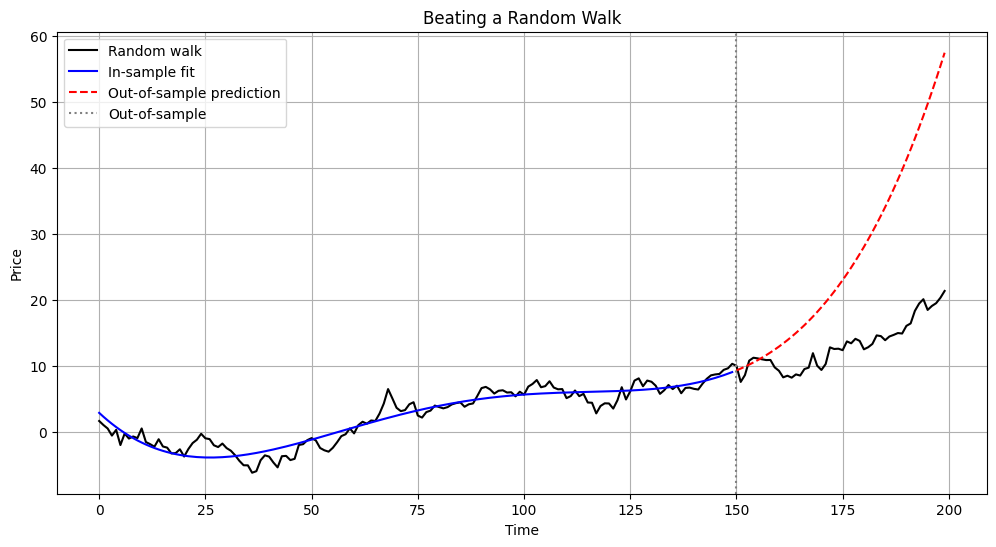

In [29]:
"""
Beating the random walk
"""


#Set seed
np.random.seed(1)

#Simulate a share price using a random walk
n_total = 200
steps = np.random.normal(loc=0, scale=1, size=n_total)
random_walk = np.cumsum(steps)

#In-sample and out-of-sample split
n_in_sample = 150
x_in = np.arange(n_in_sample)
y_in = random_walk[:n_in_sample]

x_out = np.arange(n_in_sample, n_total)
y_out = random_walk[n_in_sample:]

#Fit polynomial regression
degree = 4
poly = PolynomialFeatures(degree)
X_poly = poly.fit_transform(x_in.reshape(-1, 1))

model = LinearRegression()
model.fit(X_poly, y_in)

#Prediction
y_pred_in = model.predict(X_poly)
X_out_poly = poly.transform(x_out.reshape(-1, 1))
y_pred_out = model.predict(X_out_poly)

#Plotting
plt.figure(figsize=(12, 6))
plt.plot(np.arange(n_total), random_walk, label='Random walk', color='black')
plt.plot(x_in, y_pred_in, label='In-sample fit', color='blue')
plt.plot(x_out, y_pred_out, label='Out-of-sample prediction', color='red', linestyle='--')
plt.axvline(n_in_sample, color='gray', linestyle=':', label='Out-of-sample')
plt.title('Beating a Random Walk')
plt.xlabel('Time')
plt.ylabel('Price')
plt.legend()
plt.grid(True)
plt.savefig('Figure3.png')
plt.show()

In [30]:
"""
Energy prices
"""


#Data import
data_path = r'C:\Users\s01gk9\Documents\Current\Advanced ML and AI\Data'
figure_path = r'C:\Users\s01gk9\Documents\Current\Advanced ML and AI\Python\Section 2'
os.chdir(data_path)

#DataFrame
df = pd.read_csv('electricity_prices_import.csv')

#Convert date
df['date'] = pd.to_datetime(df['date'], format="%d %b %Y")

#Set index
df = df.set_index('date')

#Check data
print(df.head())

#Plot line chart
os.chdir(figure_path)

plt.plot(df['energy'])
plt.savefig('Figure4.png')
plt.show()





FileNotFoundError: [Errno 2] No such file or directory: 'C:\\Users\\s01gk9\\Documents\\Current\\Advanced ML and AI\\Data'

In [33]:
"""
Energy prices - returns
"""


#Data import
data_path = r'C:\Users\s01gk9\Documents\Current\Advanced ML and AI\Data'
figure_path = r'C:\Users\s01gk9\Documents\Current\Advanced ML and AI\Python\Section 2'
# os.chdir(data_path)

#DataFrame
df = pd.read_csv('electricity_prices_import.csv')

#Convert date
df['date'] = pd.to_datetime(df['date'], format="%d %b %Y")

#Set index
df = df.set_index('date')

#Returns
df['return'] = df['energy'].diff()/df['energy'].shift()

#Check data
print(df.head())

#Plot line chart
os.chdir(figure_path)

plt.plot(df['return'])
plt.savefig('Figure5.png')
plt.show()



FileNotFoundError: [Errno 2] No such file or directory: 'electricity_prices_import.csv'

In [34]:
"""
Energy prices - returns
"""


#Data import
data_path = r'C:\Users\s01gk9\Documents\Current\Advanced ML and AI\Data'
figure_path = r'C:\Users\s01gk9\Documents\Current\Advanced ML and AI\Python\Section 2'
# os.chdir(data_path)

#DataFrame
df = pd.read_csv('electricity_prices_import.csv')

#Convert date
df['date'] = pd.to_datetime(df['date'], format="%d %b %Y")

#Set index
df = df.set_index('date')

#Returns
df['return'] = df['energy'].diff()/df['energy'].shift()

#Rolling variance
df['rolling_var'] = df['return'].rolling(window = 30).var()

#Check data
print(df.head())

#Plot line chart
os.chdir(figure_path)

plt.plot(df['rolling_var'])
plt.savefig('Figure6.png')
plt.show()







FileNotFoundError: [Errno 2] No such file or directory: 'electricity_prices_import.csv'